# Prediction with a Zero Shot LLM

The original analysis was done in September 2022; the ideas of [Instruction Tuning](https://arxiv.org/pdf/2109.01652) and [RLHF](https://arxiv.org/pdf/2203.02155) for LLMs were already around but I wasn't aware of them and there weren't any models using them I could run locally back then.

Now it's 2025 and there's scores of instruction tuned models I could use - I'm curious with how it compares with the other techniques I tried.

In [13]:
import pandas as pd
import xxhash
import numpy as np

# Load data

Read in all Hacker News Stories from 2021, which [can be downloaded from Kaggle](https://www.kaggle.com/datasets/edwardjross/hackernews-2021-comments-and-stories) (extracted from the BigQuery dataset).

In [2]:
df = pd.read_parquet('../data/01_raw/hackernews2021.parquet').set_index('id')

# Split the Data

The data will be split deterministically by the by the root story.
This allows using features about the comment thread.

## Finding the root

For each comment the root can be found by walking up the parents recursively.

In [3]:
parent_dict = df['parent'].fillna(df.index.to_series()).to_dict()

root_dict = {}

for item, parent in parent_dict.items():
    while parent in parent_dict:
        grandparent = parent_dict[parent]
        if parent == grandparent:
            break
        parent = grandparent
    root_dict[item] = parent
    
df['root'] = df.index.map(root_dict)

## Deterministic Splitting

The hash of the root id with a fixed salt gives a deterministic random split.
Choose a 50% training set.

In [4]:
def bucket(s, salt='hnbooks'):
    return xxhash.xxh32_intdigest(str(s)+salt) % 100

bucket = df['root'].apply(bucket)

df['bucket'] = bucket

df['train'] = bucket < 50

# Clean the text

Hacker News comments have a subset of HTML, remove some of the markup.

Sort them roughly from longest to shortest to make batching the results more efficient, and means any errors arising from long sequences should occur early in the process.

In [5]:
import html


sample = (
    df
    .query('train & deleted.isna() & dead.isna()')
    .rename(columns={'text': 'comment_text'})
    .assign(text=lambda _: (
        (_['title'].fillna('') + '\n' + _['comment_text'].fillna('')).map(html.unescape).str.strip()
    ),
            length=lambda _: _['text'].str.len())
    .sort_values('length', ascending=False)
    .copy()
)

# Zero Shot LLM

This is really similar to the zero-shot classification prediction method, with the main benefit being there's a lot more choice in models trained on lots of data and they may work better.

In particular we'll use the probability technique as in the [Qwen 3 Ranker](https://arxiv.org/abs/2506.05176v1) asking a Yes/No question about relevance and then scoring with the probability of `Yes` relative to `Yes` and `No`:

$$ p = \frac{P({\tt Yes})}{P({\tt Yes}) + P({\tt No})} $$

We could of course use an LLM directly to do the extraction; for a start I'm just interested in whether it can detect text.

In [6]:
texts = sample['text'].to_list()

There are lots of choices of open models here (and with this approach we could even use closed weight models that provide logprobs, like Open AI).

I'm just going to pick a moderate sized model for testing - it would be interesting to compare different models.

In [7]:
from transformers import AutoTokenizer, AutoModelForCausalLM

In [8]:
model_name = "Qwen/Qwen3-4B"

In [9]:
tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModelForCausalLM.from_pretrained(
    model_name,
    torch_dtype="auto",
    device_map="auto",
)

2025-07-02 22:16:51.262583: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1751458611.275714  793816 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1751458611.278715  793816 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2025-07-02 22:16:51.289565: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


Loading checkpoint shards:   0%|          | 0/3 [00:00<?, ?it/s]

## Prompting

There are also many choices for a prompt.
I tried a few variations but ended up on this prompt with the following goals:

* The book mention should be explicit
* Start with just a Yes or No token
* It still works for a long text that is left-truncated
* Give an explanation for debugging

The instruction isn't really explicit enough, and to get better results this would need to be clearer (or even with some examples).

In [10]:
messages = [
    [{"role": "user",
      "content": f"""<text>{t}</text>
      Does the text inside the `text` XML tags explicitly reference a book by name? \
      Answer Yes followed by the title of the book if the book is directly mentioned, \
      and No otherwise - even if the title of a book appears in the text."""},]
    for t in texts
]

Apply the Chat Template to turn it into the kind of chat instruction template the model was trained on.

In [11]:
%%time
text = tokenizer.apply_chat_template(
    messages,
    tokenize=False,
    add_generation_prompt=True,
    enable_thinking=False
)

CPU times: user 54.4 s, sys: 903 ms, total: 55.3 s
Wall time: 55.3 s


Here's an example of a text with the chat template:

In [12]:
text[-100_000]

'<|im_start|>user\n<text>Why not build yourself from source?</text>\n      Does the text inside the `text` XML tags explicitly reference a book by name?       Answer Yes followed by the title of the book if the book is directly mentioned,       and No otherwise - even if the title of a book appears in the text.<|im_end|>\n<|im_start|>assistant\n<think>\n\n</think>\n\n'

## Tokenizing

## Prompting

We can get an estimate of the total tokens from a sample; it's about 300 Million tokens.

In [27]:
sample_size = 10_000

sample_idx = np.random.choice(len(text), size=sample_size)

lengths = [len(x) for x in tokenizer([text[idx] for idx in sample_idx], padding=False, return_attention_mask=False)['input_ids']]

avg_length = sum(lengths) / sample_size

f'Average Tokens: {avg_length:0.1f}, Number of Documents: {len(text)}, Total Tokens: {len(text) * avg_length: 0.2g}'

'Average Tokens: 151.3, Number of Documents: 1947961, Total Tokens:  2.9e+08'

But some are much longer than average:

In [28]:
[len(x) for x in tokenizer(text[:16], padding=False, return_attention_mask=False)['input_ids']]

[7906,
 5715,
 17024,
 3365,
 3624,
 3785,
 3513,
 2991,
 3120,
 3445,
 3062,
 2723,
 2662,
 2940,
 3379,
 2578]

## Running inference

We can't fit the whole dataset into VRAM so we'll make it smaller by:

* running in small batches of `batch_size`
* limiting the maximum length we process; this risks losing some positives but for this dataset we're only truncating one post

In [29]:
batch_size = 2
max_length = 8192
offset = 0

Make sure to truncate and pad on the left, since we're predicting the next token (we don't want that to be `<pad>`).

In [30]:
tokenizer.truncation_side = 'left'

In [31]:
%%time
model_inputs = (
    tokenizer(text[offset:offset+batch_size],
              padding=True,
              padding_side='left',
              return_tensors='pt',
              truncation=True,
              max_length=max_length,
             ).to(model.device)
)

CPU times: user 27.9 ms, sys: 21.9 ms, total: 49.8 ms
Wall time: 37.8 ms


The outputs are in the shape `batch_size x length`

In [32]:
model_inputs['input_ids'].shape

torch.Size([2, 7906])

We can then run a model inference to get the logits

In [33]:
import torch

In [34]:
with torch.inference_mode():
    logits = model(**model_inputs).logits[:,-1].cpu()

And then take the softmax to turn these into probabilities

In [35]:
probs = logits.softmax(dim=-1)

And then calcualate the relative probability of `Yes` out of `Yes` and `No`.

The model is very confident these are not relevance.

In [36]:
yes_token = tokenizer.vocab['Yes']
no_token = tokenizer.vocab['No']

In [37]:
p_yes = probs[:, yes_token]
p_no = probs[:, no_token]

p = p_yes / (p_yes + p_no)
p = [float(pi) for pi in p]
p

[3.583409124985337e-10, 3.1650415621697903e-10]

Instead of just getting one token we can generate a sequence of tokens to get the models rationale.

Note that best practice is to get the model to give the reasoning first, but in this case the decision is often simple and it breaks our ability to get the probability score.

In [38]:
preds = model.generate(**model_inputs, max_new_tokens=64)

In [39]:
tokenizer.batch_decode(preds[:,model_inputs['input_ids'].size(-1):], skip_special_tokens=True)

['No. The text does not explicitly reference a book by name. While it mentions various projects, technologies, and research papers, it does not directly name a specific book.',
 'No. The text does not explicitly reference a book by name. While the text discusses Angular and related technologies, it does not mention any specific book title.']

## Scaling up

Let's now run it over the whole dataset. This took just under 18 hours on a RTX 3090.

In [40]:
from tqdm.notebook import tqdm, trange

In [36]:
%%time
output_probs = []

for i in trange(0, len(text), batch_size):
    batch = text[i:i + batch_size]

    model_inputs = (
    tokenizer(batch,
              padding=True,
              padding_side='left',
              return_tensors='pt',
              truncation=True,
              max_length=max_length,
             ).to(model.device)
    )

    with torch.inference_mode():
        logits = model(**model_inputs).logits[:,-1].cpu()

    probs = logits.softmax(dim=-1)
    p_yes = probs[:, yes_token]
    p_no = probs[:, no_token]

    p = p_yes / (p_yes + p_no)
    p = [float(pi) for pi in p]
    output_probs += p

  0%|          | 0/973981 [00:00<?, ?it/s]

CPU times: user 23h 16min 2s, sys: 1h 37min 17s, total: 1d 53min 19s
Wall time: 17h 49min 52s


Save the output

In [43]:
sample['qwen_4b_prob'] = output_probs

In [44]:
sample[['qwen_4b_prob']].to_parquet('../data/02_intermediate/llm_predictions.parquet',
                                          compression='gzip', engine='pyarrow')

## Analysis

We can now look at the distribution of the predictions

In [41]:
qwen_4b_prob = pd.read_parquet('../data/02_intermediate/llm_predictions.parquet')

sample['qwen_4b_prob'] = qwen_4b_prob

In [42]:
import numpy as np
import matplotlib.pyplot as plt

The model predictions tend to be very confident shooting from <1% to >99% between the 92nd and 97th percentiles.

0.50th percentile: 2.1e-09
0.90th percentile: 0.00026
0.92th percentile: 0.0025
0.95th percentile: 0.44
0.97th percentile: 1
0.99th percentile: 1


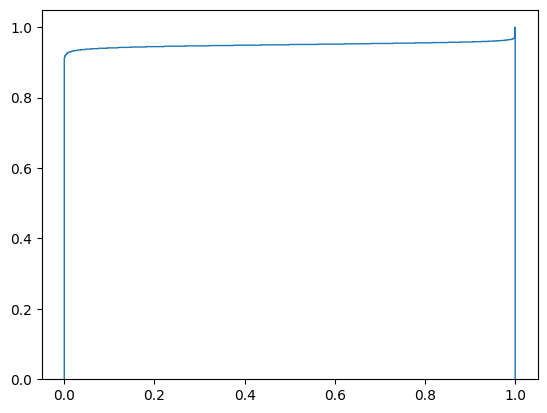

In [43]:
plt.hist(qwen_4b_prob, bins=1000, density=True, cumulative=True, histtype="step");

quantiles = [0.5, 0.9, 0.92, 0.95, 0.97, 0.99]
for q, p in zip(quantiles, np.quantile(qwen_4b_prob, q=quantiles)):
    print(f'{q:0.2f}th percentile: {p:0.2g}')

In [56]:
examples = sample.query('url.isna() & qwen_4b_prob > 0.97').sample(20, random_state=42)

In [60]:
example_messages = [
    [{"role": "user",
      "content": f"""<text>{t}</text>
      Does the text inside the `text` XML tags explicitly reference a book by name? \
      Answer Yes followed by the title of the book if the book is directly mentioned, \
      and No otherwise - even if the title of a book appears in the text."""},]
    for t in examples['text']
]

In [61]:
example_text = tokenizer.apply_chat_template(
    example_messages,
    tokenize=False,
    add_generation_prompt=True,
    enable_thinking=False
)

In [62]:
model_inputs = (
    tokenizer(example_text,
              padding=True,
              padding_side='left',
              return_tensors='pt',
              truncation=True,
              max_length=max_length,
             ).to(model.device)
)

In [77]:
model_inputs['input_ids'].size(-1)

352

In [63]:
model_outputs = model.generate(**model_inputs, max_new_tokens=64)

In [78]:
token_offset = model_inputs['input_ids'].size(-1)

In [81]:
explanations = tokenizer.batch_decode(model_outputs[:, token_offset:], skip_special_tokens=True)

Here's some explanations

In [91]:
for idx, (id, t) in enumerate(examples.iterrows()):
    print(f'{idx}: Probability {t.qwen_4b_prob:0.2%} ng in science. In fact, the default position should be disbelief. There are experiments and explanations. Some explanations keep working after many experiments. Many do not. Those explanations that survive m(https://news.ycombinator.com/item?id={id}):\nText: {t.text}\nReasoning: {explanations[idx]}\n')

0: Probability 100.00% (https://news.ycombinator.com/item?id=29618000):
Text: There's no need to believe anything in science. In fact, the default position should be disbelief. There are experiments and explanations. Some explanations keep working after many experiments. Many do not. Those explanations that survive many attempts at disproof become accepted. It doesn't happen "all of a sudden."<p>The claim that the Bible explains creation does not stand up too well to experiment in this regard.
Reasoning: Yes  
The Bible

1: Probability 100.00% (https://news.ycombinator.com/item?id=29564978):
Text: "I'm sorry, Dave. I'm afraid I can't do that."
Reasoning: Yes  
The title of the book is "2001: A Space Odyssey".

2: Probability 100.00% (https://news.ycombinator.com/item?id=26040036):
Text: Petzold's Code is a popularization aimed at non-technical readers, as you said.  ECS is a textbook aimed at college-level CS and Comp. Eng. students and goes into sufficient technical depth for the read

By my judgements it gets 6/20 correct, which is a similar precision to my MiniLM NLI classifier or Work of Art detector that ran much faster.

0. Correct: The bible
1. Incorrect: the reference is oblique, the title isn't directly mentioned
2. Correct: Petzold's Code
3. Incorrect: Jacobin is a news outlet
4. Incorrect: PMD User's Guide is not a book
5. Incorrect: German Civil Code isn't a book
6. Incorrect: The New York Times isn't a book
7. Incorrect: Not a book
8. Correct: How to Talk So Kids Will Listen, How to Listen So Kids Will Talk
9. Incorrect
10. Incorrect: BPA is a chemical
11. Incorrect
12. Correct: I'm Just Here for the Food
13. Incorrect: Theo is a person's name
14. Incorrect: A Tale of Three Kings is just the title of an article
15. Correct: Collapse
16. Incorrect: This is just referencing the year an article was published
17. Incorrect: Alfred is a productivity app
18. Incorrect: Law enforcement guide is not a book
19. Correct: Economic and Philosophic Manuscripts of 1844


One of the neat things about the prevalence of LLMs is there's a bunch of obvious things I could do to make this better:

* Give more explicit instructions in the prompt
* Give more context from the parent message
* Run RAG (e.g. against Open Books or Wikipedia) to give context
* Run a larger model

## Overlap

Let's repeat the overlap analysis from 105, adding in our new heuristic:

In [92]:
ask_hn_data = pd.read_parquet('../data/02_intermediate/ask_hn_books.parquet')
seed_data = pd.read_parquet('../data/02_intermediate/seed_books.parquet')
zero_shot_data = pd.read_parquet('../data/02_intermediate/zero_shot_contains_book_title_predictions.parquet')
work_of_art_data = pd.read_parquet('../data/02_intermediate/work_of_art_predictions.parquet')

In [93]:
sample = (
    sample
    .merge(ask_hn_data, left_index=True, right_index=True, how='left', validate='1:1')
    .merge(seed_data, left_index=True, right_index=True, how='left', validate='1:1')
    .merge(zero_shot_data, left_index=True, right_index=True, how='left', validate='1:1')
    .merge(work_of_art_data, left_index=True, right_index=True, how='left', validate='1:1')
)

In [94]:
sample['seed_sibling'] = sample['seed_sibling'] & ~sample['seed_book']

In [95]:
sample['zero_shot_80'] = sample['prob'] > 0.8

In [146]:
sample['llm_97'] = sample['qwen_4b_prob'] > 0.97

Our zero shot LLM method has found more positives than any other method (though maybe our threshold should have been higher).

In [144]:
(
    sample
    .filter(regex='ask_hn|seed_|work_of_art|zero_shot_80|llm_97')
    .mean()
    .sort_values(ascending=False)
    .to_frame()
    .T
    .style.format('{:0.2%}')
)

,llm_97,work_of_art,zero_shot_80,seed_sibling,seed_book,seed_child,seed_parent,ask_hn_books
0,3.10%,2.72%,2.59%,0.67%,0.06%,0.06%,0.05%,0.04%


In [134]:
def confidence(x, y):
    return (sample[x] & sample[y]).sum() / sample[x].sum()

One thing to notice is our Qwen 4B model captures more of other models than any other approach.
This is partly because it's a bit larger than the other categories, but it still captures substantially more of the Seed Books than the NLI Zero Shot approach (potentially because it has more world knowledge).

The bottom right matrix is particularly interesting that Work of Art, Zero Shot 80 and LLM 97 have similar relations between each other:
* LLM 97 contains 36% of both Work of Art and Zero Shot 80
* Work of Art and Zero Shot 80 both contain about 1/4 of LLM 97 and each other

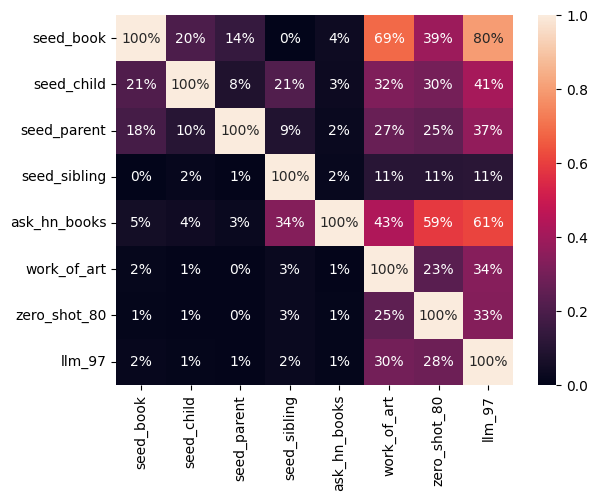

In [145]:
import seaborn as sns

cols = ['seed_book', 'seed_child', 'seed_parent', 'seed_sibling', 'ask_hn_books', 'work_of_art', 'zero_shot_80', 'llm_97']

confidences = pd.DataFrame(index=cols, columns=cols, dtype='float')

for col1 in cols:
    for col2 in cols:
        confidences.loc[col1, col2] = confidence(col1, col2)
        
ax = sns.heatmap(confidences, annot=True, fmt="0.0%")

So a 4B parameter LLM with a simple prompt works pretty well, but not dramatically better than our MiniLM NLI model.
However it has the advantage that we could use a the LLM to extract the title and author in a structured format, which we can't do with the NLI model (before we used a question answering model for a similar task).